<a href="https://colab.research.google.com/github/akshin-kuvshin/numerical-methods/blob/main/lab2/lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №2. Многочлены Лагранжа, Ньютона и схема Эйткена

## Выполнил: Данила Аксёнов, гр. 932420

## Вариант: 1

<hr>

## **Задание 2**

1) Найти приближенное значение функции в точке $ x_* $ по таблице значений $ (x_i, y_i) $, используя многочлен Лагранжа;

2) Построить график многочлена Лагранжа с табличными значениями и график вычислительной погрешности;

3) Считая, что табличные значения заданы с верными знаками, оценить неустранимую погрешность результата.

## Решение:

In [163]:
import numpy as np
from matplotlib import pyplot as plt
print('Setup completed')

Setup completed


### Исходные данные:

In [164]:
x = np.array([0.35, 0.48, 0.97, 1.08, 1.18, 1.35])
y = np.array([1.419, 1.616, 2.637, 2.944, 3.254, 4.119])
n = len(x) # == len(y)

x_star = 0.58

### Аппроксимируем значение функции в точке $ x_* $:

In [165]:
def f_lagrange(x_0):
    y_0 = 0.

    for i in range(n):
        numerator = 1.
        denominator = 1.
        for j in range(n):
            if i == j:
                continue
            numerator *= (x_0 - x[j])
            denominator *= (x[i] - x[j])
        l_i = numerator / denominator
        y_0 += y[i] * l_i

    return y_0

In [166]:
y_star = f_lagrange(x_star)
y_star

np.float64(1.7392512750270868)

Получили $ y_* \approx 1.73925128 $.

### Строим график интерполяционного многочлена Лагранжа:

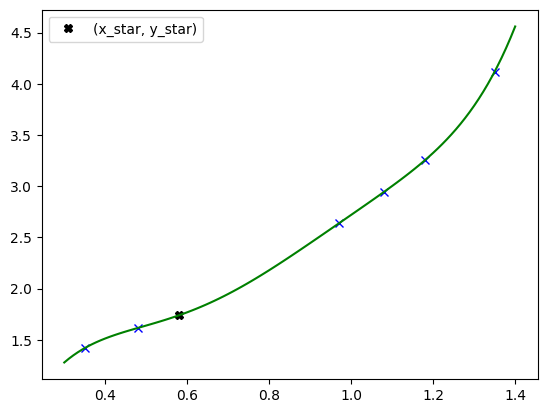

In [167]:
x_min = 0.3
x_max = 1.4
m = 100

for x_i, y_i in zip(x, y):
    plt.plot(x_i, y_i, 'x', color='blue')

plt.plot(x_star, y_star, 'X', color='black', label='(x_star, y_star)')

x_ = np.linspace(x_min, x_max, num=m)
y_ = np.array(list(map(f_lagrange, x_)))
plt.plot(x_, y_, '-', color='green')

plt.legend()
plt.show()

### Оцениваем неустранимую погрешность результата:

Все числа будем хранить в кортежах следующего вида: $ (x, \Delta x*, \delta x*) $.

Формулы для следующих 6 функций взяты из лекций.

In [168]:
# получить абсолютную и относительную погрешность узла x[i]
def get_x_error(x_i):
    n = 3 if x_i > 1 else 2
    m = 0 if x_i > 1 else -1
    k = m - n + 1
    abs_error = 0.5 * 10 ** k
    rel_error = abs_error / abs(x_i)
    return (x_i, abs_error, rel_error)

In [169]:
# получить абсолютную и относительную погрешность значения в узле y[i]
def get_y_error(y_i):
    n = 4
    m = 0
    k = m - n + 1
    abs_error = 0.5 * 10 ** k
    rel_error = abs_error / abs(y_i)
    return (y_i, abs_error, rel_error)

In [170]:
# получить абсолютную и относительную погрешность суммы многих слагаемых
# ts = [t_1, t_2, ..., t_n]
# t_1 + t_2 + ... + t_n
def get_sum_error(ts):
    res = sum(t[0] for t in ts)
    abs_error = sum(t[1] for t in ts)
    rel_error = max(t[2] for t in ts)
    return (res, abs_error, rel_error)

In [171]:
# получить абсолютную и относительную погрешность разности
# t1 - t2
def get_diff_error(t1, t2):
    res = t1[0] - t2[0]
    abs_error = t1[1] + t2[1]
    rel_error = (abs(t1[0]) * t1[2] + abs(t2[0]) * t2[2]) / abs(res)
    return (res, abs_error, rel_error)

In [172]:
# получить абсолютную и относительную погрешность произведения многих сомножителей
# ts = [t_1, t_2, ..., t_n]
# t_1 * t_2 * ... * t_n
def get_prod_error(ts):
    res = 1.
    for t in ts:
        res *= t[0]
    rel_error = sum(t[2] for t in ts)
    abs_error = abs(res) * rel_error
    return (res, abs_error, rel_error)

In [173]:
# получить абсолютную и относительную погрешность частного
# t1 / t2
def get_quotient_error(t1, t2):
    res = t1[0] / t2[0]
    abs_error = (t1[1] + abs(res) * t2[1]) / abs(t2[0])
    rel_error = t1[2] + t2[2]
    return (res, abs_error, rel_error)

In [174]:
x_error = np.array(list(map(get_x_error, x)))
y_error = np.array(list(map(get_y_error, y)))

def get_f_lagrange_inherent_error(x_0):
    x_0_error = get_x_error(x_0)

    y_0_elems_error = []
    for i in range(n):
        numerator_elems_error = []
        denominator_elems_error = []
        for j in range(n):
            if i == j:
                continue
            numerator_elems_error.append(get_diff_error(x_0_error, x_error[j]))
            denominator_elems_error.append(get_diff_error(x_error[i], x_error[j]))
        numerator_error = get_prod_error(numerator_elems_error)
        denominator_error = get_prod_error(denominator_elems_error)

        li_error = get_quotient_error(numerator_error, denominator_error)
        y_0_elems_error.append(get_prod_error((y_error[i], li_error)))

    y_0_error = get_sum_error(y_0_elems_error)
    return y_0_error

In [175]:
y_star_error = get_f_lagrange_inherent_error(x_star)
y_star_error

(np.float64(1.7392512750270868),
 np.float64(9.426493955965267),
 np.float64(0.45725422787057324))

Получили неутешительную верхнюю оценку: $ \Delta_н \le 9.42649396 $.

Консультация с ИИ не помогла выявить ошибки в расчётном коде, которые, по моему мнению, приводят к такому большому значению.

### Строим график вычислительной погрешности интерполяции с помощью многочлена Лагранжа:

In [176]:
def get_f_lagrange_method_error(x_0):
    error = 0.

    for i in range(n):
        numerator = 1.
        denominator = 1.
        for j in range(n):
            if i == j:
                continue
            numerator *= (x_0 - x[j])
            denominator *= (x[i] - x[j])
        l_i = numerator / denominator
        error += y_error[i][1] * abs(l_i)

    return error

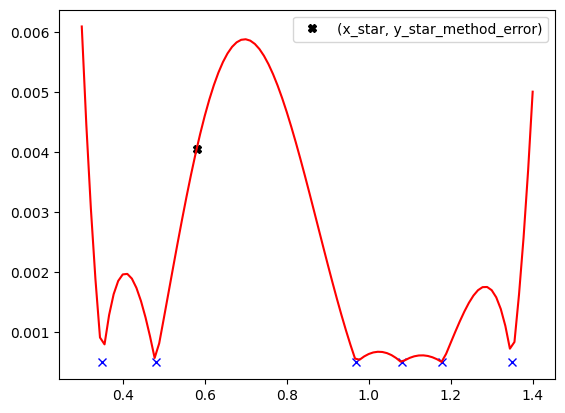

In [177]:
y_method_error = np.array(list(map(get_f_lagrange_method_error, x)))
for x_i, dy_i in zip(x, y_method_error):
    plt.plot(x_i, dy_i, 'x', color='blue')

y_star_method_error = get_f_lagrange_method_error(x_star)
plt.plot(x_star, y_star_method_error, 'X', color='black', label='(x_star, y_star_method_error)')

y__method_error = np.array(list(map(get_f_lagrange_method_error, x_)))
plt.plot(x_, y__method_error, '-', color='red')

plt.legend()
plt.show()

<hr>

## **Задание 3**

1) Найти приближенное значение функции в точке $ x_* $ по схеме Эйткена;

2) Оценить неустранимую погрешность результата.

## Решение:

### Аппроксимируем значение функции в точке $ x_* $:

In [178]:
# строим таблицу функций L(x)
# L[i][len] = L_{(i-len+1)..i}, т.е. аппроксимационная функция на основе узлов с номерами от (i-len+1) до i
L = []
for i in range(n):
    L.append([])
    for len_ in range(i + 2):
        if len_ < 2:
            L[i].append(lambda x_0: 0)
            continue
        if len_ == 2:
            L[i].append(lambda x_0, i_=i: (y[i_ - 1] * (x[i_] - x_0) - y[i_] * (x[i_ - 1] - x_0)) / (x[i_] - x[i_ - 1]))
            continue
        L[i].append(lambda x_0, i_=i, len__=len_: (L[i_ - 1][len__ - 1](x_0) * (x[i_] - x_0) - L[i_][len__ - 1](x_0) * (x[i_ - len__ + 1] - x_0)) / (x[i_] - x[i_ - len__ + 1]))

In [179]:
y_star = L[-1][-1](x_star)
y_star

np.float64(1.7392512750270879)

Снова получили $ y_* \approx 1.73925128 $.

Результат совпадает с результатом интерполяционного многочлена Лагранжа.

### Оцениваем неустранимую погрешность результата:

In [180]:
# строим таблицу функций ошибок L_error(x)
# каждая L_error[i][len]:
# 1) соответствует каждой L[i][len];
# 2) возвращает тройку (res, abs_error, rel_error) (подробнее см. выше), соответствующую результату L[i][len](x)
L_error = []
for i in range(n):
    L_error.append([])
    for len_ in range(i + 2):
        if len_ < 2:
            L_error[i].append(lambda x_0: (0., 0., float('nan')))
            continue
        if len_ == 2:
            L_error[i].append(lambda x_0, i_=i:
                get_quotient_error(
                    get_diff_error(
                        get_prod_error((
                            y_error[i_ - 1],
                            get_diff_error(x_error[i_], get_x_error(x_0))
                        )),
                        get_prod_error((
                            y_error[i_],
                            get_diff_error(x_error[i_ - 1], get_x_error(x_0))
                        ))
                    ),
                    get_diff_error(x_error[i_], x_error[i_ - 1])
                )
            )
            continue
        L_error[i].append(lambda x_0, i_=i, len__=len_:
            get_quotient_error(
                get_diff_error(
                    get_prod_error((
                        L_error[i_ - 1][len__ - 1](x_0),
                        get_diff_error(x_error[i_], get_x_error(x_0))
                    )),
                    get_prod_error((
                        L_error[i_][len__ - 1](x_0),
                        get_diff_error(x_error[i_ - len__ + 1], get_x_error(x_0))
                    ))
                ),
                get_diff_error(x_error[i_], x_error[i_ - len__ + 1])
            )
        )

In [181]:
y_star_error = L_error[-1][-1](x_star)
y_star_error

(np.float64(1.7392512750270879),
 np.float64(0.9692623682155436),
 np.float64(0.5572871396632714))

По сравнению с оценкой неустранимой погрешности интерполирования с помощью многочлена Лагранжа, оценка в случае интерполирования с помощью схемы Эйткена в разы лучше: $ \Delta_н \le 0.96926237 $.

<hr>

## **Задание 4**

1) Найти приближенное значение функции в точке $ x_* $ по таблице значений $ (x_i, y_i) $, используя многочлен Ньютона;

2) Построить график многочлена Ньютона с табличными значениями и график вычислительной погрешности;

3) Считая, что табличные значения заданы с верными знаками, оценить неустранимую погрешность результата.

## Решение:

### Аппроксимируем значение функции в точке $ x_* $:

In [182]:
# строим таблицу разделённых разностей f
# f[i][k] = f(x_i, x_{i+1}, ..., x_{i+k-1}, x_{i+k}) - разделённая разность k-того порядка
# для удобства будем считать, что f[i][0] = f(x_i) = y_i
f = []
for k in range(n):
    for i in range(n - k):
        if k == 0:
            f.append([])
            f[i].append(y[i])
        else: # k >= 1
            f[i].append((f[i + 1][k - 1] - f[i][k - 1]) / (x[i + k] - x[i]))

In [183]:
def f_newton(x_0):
    y_0 = y[0]
    for k in range(1, n):
        p = 1.
        for i in range(k):
            p *= x_0 - x[i]
        y_0 += p * f[0][k]
    return y_0

In [184]:
y_star = f_newton(x_star)
y_star

np.float64(1.739251275027088)

И снова получаем такой же результат, как и у предыдущих двух методов: $ y_* \approx 1.73925128 $.

### Строим график интерполяционного многочлена Ньютона:

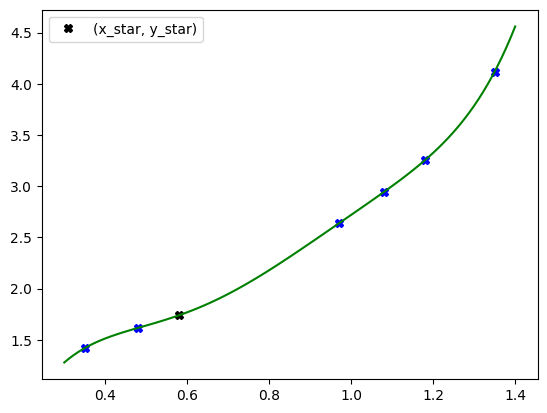

In [185]:
for x_i, y_i in zip(x, y):
    plt.plot(x_i, y_i, 'X', color='blue')

plt.plot(x_star, y_star, 'X', color='black', label='(x_star, y_star)')

y_ = np.array(list(map(f_newton, x_)))
plt.plot(x_, y_, '-', color='green')

plt.legend()
plt.show()

График многочлена Ньютона совпадает с графиком многочлена Лагранжа, что логично, т.к. они являются тождественными, но с разными аналитическими выражениями.

### Строим график вычислительной погрешности интерполяции с помощью многочлена Ньютона:

За вычислительную погрешность в данном случае примем остаточный член формулы Ньютона (выражение (2.27) в учебнике), причём будем брать его со знаком (т.е. не по модулю), т.к. тогда график вычислительной погрешности получается визуально более непрерывным, хоть и не теряет в информативности.

In [186]:
def get_f_newton_method_error(x_0):
    error = 1.
    for i in range(n):
        error *= x_0 - x[i]

    # считаем дополнительную верхнюю строку (-1-ую = минус первую) в таблице разделённых разностей f
    # fx[k] = f(x, x_0, x_1, ..., x_{k-2}, x_{k-1}) - разделённая разность k-того порядка
    fx = []
    for k in range(n + 1):
        if k == 0:
            fx.append(f_newton(x_0)) # по-хорошему здесь нужно истинное значение исходной функции в точке x_0,
                                     # но, за неимением лучшего варианта, примем его за значение интерполяции
                                     # в той же точке - этим объясняется порядок 1e-16 на графике (по сути,
                                     # вычисляем модифицированную машинную погрешность)
        else: # k >= 1
            fx.append((f[0][k - 1] - fx[k - 1]) / (x[k - 1] - x_0))

    error *= fx[-1]
    return error

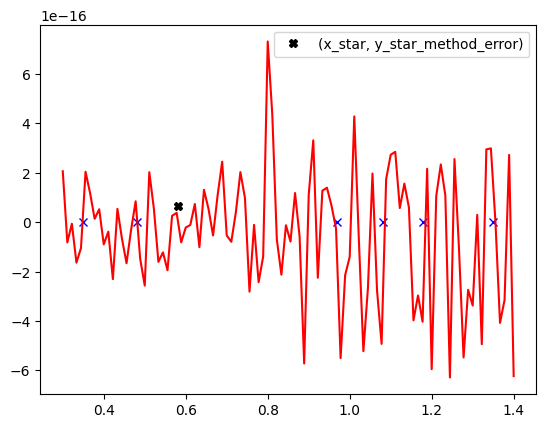

In [187]:
y_method_error = np.zeros_like(x) # не можем посчитать через get_f_newton_method_error,
                                  # потому что разделённая разность, два аргумента которой равны, не определена,
                                  # поэтому условно примем вычислительную погрешность интерполяции
                                  # в известных нам узлах (x_i, y_i) за 0 (ноль)
for x_i, dy_i in zip(x, y_method_error):
    plt.plot(x_i, dy_i, 'x', color='blue')

y_star_method_error = get_f_newton_method_error(x_star)
plt.plot(x_star, y_star_method_error, 'X', color='black', label='(x_star, y_star_method_error)')

y__method_error = np.array(list(map(get_f_newton_method_error, x_)))
plt.plot(x_, y__method_error, '-', color='red')

plt.legend()
plt.show()

Как и по графику вычислительной погрешности интерполирования с помощью многочлена Лагранжа, по данному графику можно заметить, что модуль вычислительной погрешности тем больше, чем дальше ближайший известный узел $ (x_i, y_i) $:

1) Левее узла $ (x_0, y_0) $ и правее узла $ (x_5, y_5) $ модуль вычислительной погрешности начинает резко расти;

2) В точке $ x' \approx 0.8 $ модуль вычислительной погрешности достигает локального максимума, т.к. отрезок между соседними узлами $ (x_1, y_1) = (0.48, 1.616) $ и $ (x_2, y_2) = (0.97, 2.637) $ велик: $ x_2 - x_1 = 0.97 - 0.48 = 0.49 $.

### Оцениваем неустранимую погрешность результата:

___Напоминание:___ все числа, как и раньше, будем хранить в кортежах следующего вида: $ (x, \Delta x*, \delta x*) $.

In [188]:
f_error = []
for k in range(n):
    for i in range(n - k):
        if k == 0:
            f_error.append([])
            f_error[i].append(y_error[i])
        else: # k >= 1
            f_error[i].append(
                get_quotient_error(
                    get_diff_error(f_error[i + 1][k - 1], f_error[i][k - 1]),
                    get_diff_error(x_error[i + k], x_error[i])
                )
            )

In [189]:
def get_f_newton_inherent_error(x_0):
    x_0_error = get_x_error(x_0)

    y_0_elems_error = [y_error[0]]
    for k in range(1, n):
        p_elems_error = []
        for i in range(k):
            p_elems_error.append(get_diff_error(x_0_error, x_error[i]))
        p_error = get_prod_error(p_elems_error)
        y_0_elems_error.append(get_prod_error((p_error, f_error[0][k])))

    y_0_error = get_sum_error(y_0_elems_error)
    return y_0_error

In [190]:
get_f_newton_inherent_error(x_star)

(np.float64(1.739251275027088),
 np.float64(0.18708552674997225),
 np.float64(100.02447500127629))

Оценка неустранимой погрешности интерполирования с помощью многочлена Ньютона наилучшая (наименьшая) среди всех предыдущих: $ \Delta_н \le 0.18708553 $.

<hr>

## **Вывод**

В данной лабораторной работы было проведено интерполирование неизвестной функции в точке $ x_* = 0.58 $ с помощью многочлена Лагранжа, схемы Эйткена и многочлена Ньютона. Все три метода дали идентичный результат: $ y_* \approx 1.73925128 $ (различия могут быть только на уровне погрешности округления); графики многочленов Лагранжа и Ньютона также совпали.

По графикам вычислительной погрешности интерполирования с помощью многочленов Лагранжа и Ньютона видно, что точность интерполяции существенно зависит от положения точки $ x_* $ относительно известных узлов $ (x_i, y_i) $ и их распределения. В частности, неравномерность расположения узлов приводит к увеличению чувствительности интерполяции в отдельных областях.

Интерполяционная формула Ньютона даёт минимальную неустранимую погрешность при минимальных требуемых вычислениях для масштабирования (добавления новых известных узлов), что заставляет меня назвать этот метод наиболее предпочтительным среди всех рассмотренных.